# Homework #6 — Pre-processing the Adult Dataset

## 0. Setup

In [153]:
import json
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

FIG_DIR = pathlib.Path("figures")
FIG_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "font.size": 10,
})
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.1


In [154]:
df_raw = pd.read_csv("adult.csv")
df = df_raw.copy()

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 48,842 rows x 15 columns


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


# 1 Exploratory Data

## 1.1 Descriptive statistics

In [155]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]

print("Numerical  :", num_cols)
print("Categorical:", cat_cols)

desc = pd.DataFrame({
    "count":  df[num_cols].count(),
    "mean":   df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode":   df[num_cols].mode().iloc[0],
    "std":    df[num_cols].std(),
    "var":    df[num_cols].var(),
    "min":    df[num_cols].min(),
    "max":    df[num_cols].max(),
    "skew":   df[num_cols].skew(),
    "kurtosis": df[num_cols].kurtosis(),
})
desc["cv"] = desc["std"] / desc["mean"]
desc.round(3)

Numerical  : ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country', 'income']


,count,mean,median,mode,std,var,min,max,skew,kurtosis,cv
age,48842,38.644,37.0,36,13.711,1.879780e+02,17,90,0.558,-0.184,0.355
fnlwgt,48842,189664.135,178144.5,203488,105604.025,1.115221e+10,12285,1490400,1.439,6.058,0.557
educational-num,48842,10.078,10.0,9,2.571,6.610000e+00,1,16,-0.317,0.626,0.255
capital-gain,48842,1079.068,0.0,0,7452.019,5.553259e+07,0,99999,11.895,152.693,6.906
capital-loss,48842,87.502,0.0,0,403.005,1.624127e+05,0,4356,4.570,20.014,4.606
hours-per-week,48842,40.422,40.0,40,12.391,1.535480e+02,1,99,0.239,2.951,0.307


In [156]:
skew_rank = desc["skew"].abs().sort_values(ascending=False)
skew_rank.round(3)

capital-gain       11.895
capital-loss        4.570
fnlwgt              1.439
age                 0.558
educational-num     0.317
hours-per-week      0.239
Name: skew, dtype: float64

In [157]:
skew_rank = desc["var"].abs().sort_values(ascending=False)
skew_rank.round(3)

fnlwgt             1.115221e+10
capital-gain       5.553259e+07
capital-loss       1.624127e+05
age                1.879780e+02
hours-per-week     1.535480e+02
educational-num    6.610000e+00
Name: var, dtype: float64

### Interpretation — variance and skew

**Highest variance** 
- fnlwgt 

**Significant skew** 

* capital-gain
* capital-loss
* fnlwgt
* age

## 1.2 Data-quality audit

### 1.2.1 Data type of every column

In [158]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "kind": ["Numerical" if c in num_cols else "Categorical" for c in df.columns],
    "n_unique": df.nunique(),
})
audit

,dtype,kind,n_unique
age,int64,Numerical,74
workclass,str,Categorical,9
fnlwgt,int64,Numerical,28523
education,str,Categorical,16
educational-num,int64,Numerical,16
marital-status,str,Categorical,7
occupation,str,Categorical,15
relationship,str,Categorical,6
race,str,Categorical,5
gender,str,Categorical,2


### 1.2.2 Missing values

In [159]:
print("NaN reported by pandas:", int(df.isna().sum().sum()))

sentinel = "?"
miss = pd.DataFrame({
    "n_missing": {c: int((df[c].astype(str).str.strip() == sentinel).sum()) for c in cat_cols}
})
miss = miss.sort_values("n_missing", ascending=False)
miss

NaN reported by pandas: 0


,n_missing
occupation,2809
workclass,2799
native-country,857
marital-status,0
education,0
relationship,0
race,0
gender,0
income,0


In [160]:
mask = df[cat_cols].apply(lambda s: s.astype(str).str.strip() == sentinel)
rows_any = int(mask.any(axis=1).sum())
both_wc_occ = int((mask["workclass"] & mask["occupation"]).sum())
print(f"workclass and occupation both missing: {both_wc_occ:,}")

workclass and occupation both missing: 2,799


missingness is not random noise

- where workclass and occupation is missing has 2799 row that is 100% of workclass missing row so missing may cause by state of occupation like re-tired or exit.

## 1.3 Categorical analysis

### 1.3.1 Every distinct label in every categorical column

In [161]:
for c in cat_cols:
    labels = sorted(df[c].astype(str).str.strip().unique())
    print(f"\n{c}  {len(labels)}")
    print("  , ".join(labels))



workclass  9
?  , Federal-gov  , Local-gov  , Never-worked  , Private  , Self-emp-inc  , Self-emp-not-inc  , State-gov  , Without-pay

education  16
10th  , 11th  , 12th  , 1st-4th  , 5th-6th  , 7th-8th  , 9th  , Assoc-acdm  , Assoc-voc  , Bachelors  , Doctorate  , HS-grad  , Masters  , Preschool  , Prof-school  , Some-college

marital-status  7
Divorced  , Married-AF-spouse  , Married-civ-spouse  , Married-spouse-absent  , Never-married  , Separated  , Widowed

occupation  15
?  , Adm-clerical  , Armed-Forces  , Craft-repair  , Exec-managerial  , Farming-fishing  , Handlers-cleaners  , Machine-op-inspct  , Other-service  , Priv-house-serv  , Prof-specialty  , Protective-serv  , Sales  , Tech-support  , Transport-moving

relationship  6
Husband  , Not-in-family  , Other-relative  , Own-child  , Unmarried  , Wife

race  5
Amer-Indian-Eskimo  , Asian-Pac-Islander  , Black  , Other  , White

gender  2
Female  , Male

native-country  42
?  , Cambodia  , Canada  , China  , Columbia  , Cuba

### 1.3.2 education and educational-num

In [162]:
edu_map = (df.groupby("education")["educational-num"]
             .agg(["min", "max", "nunique", "size"])
             .sort_values("min"))
edu_map

,min,max,nunique,size
education,,,,
Preschool,1,1,1,83
1st-4th,2,2,1,247
5th-6th,3,3,1,509
7th-8th,4,4,1,955
9th,5,5,1,756
10th,6,6,1,1389
11th,7,7,1,1812
12th,8,8,1,657
HS-grad,9,9,1,15784


Education and education-num is one to one map on each other so keep it together would be redundant and not usefull for creating model.


#  Visual Discovery and Outlier Handling

## 2.1 Histograms

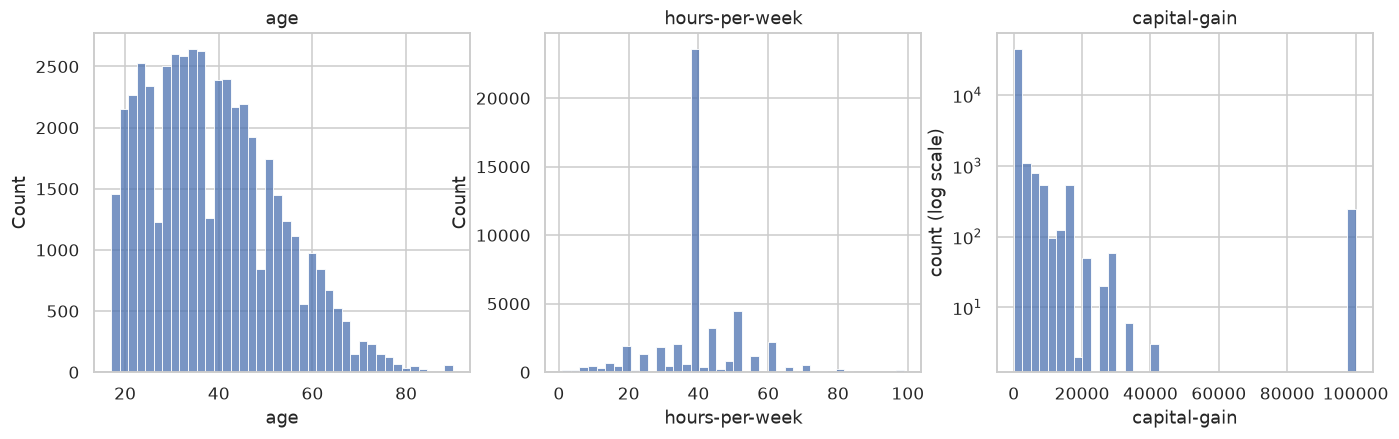

age skew = 0.56 , hours-per-week skew = 0.24 , capital-gain skew = 11.89


In [176]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["age"], bins=40, ax=axes[0])
axes[0].set_title(f"age")

sns.histplot(df["hours-per-week"], bins=40, ax=axes[1])
axes[1].set_title(f"hours-per-week")

sns.histplot(df["capital-gain"], bins=40, ax=axes[2])
axes[2].set_title(f"capital-gain")
axes[2].set_yscale("log")
axes[2].set_ylabel("count (log scale)")

plt.show()
print("age skew = {:.2f} , hours-per-week skew = {:.2f} , capital-gain skew = {:.2f}".format(df['age'].skew(), df['hours-per-week'].skew(), df['capital-gain'].skew()))

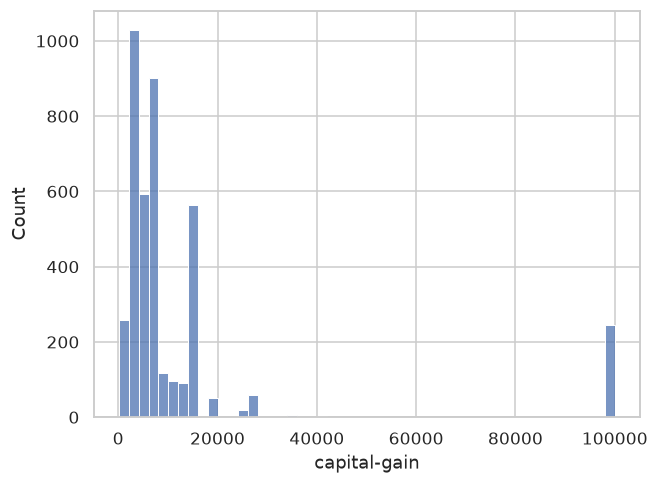

In [164]:
nz = df.loc[df["capital-gain"] > 0, "capital-gain"]
fig, axes = plt.subplots()
sns.histplot(nz, bins=50)
plt.show()

## 2.2 Box plots for the numerical variables

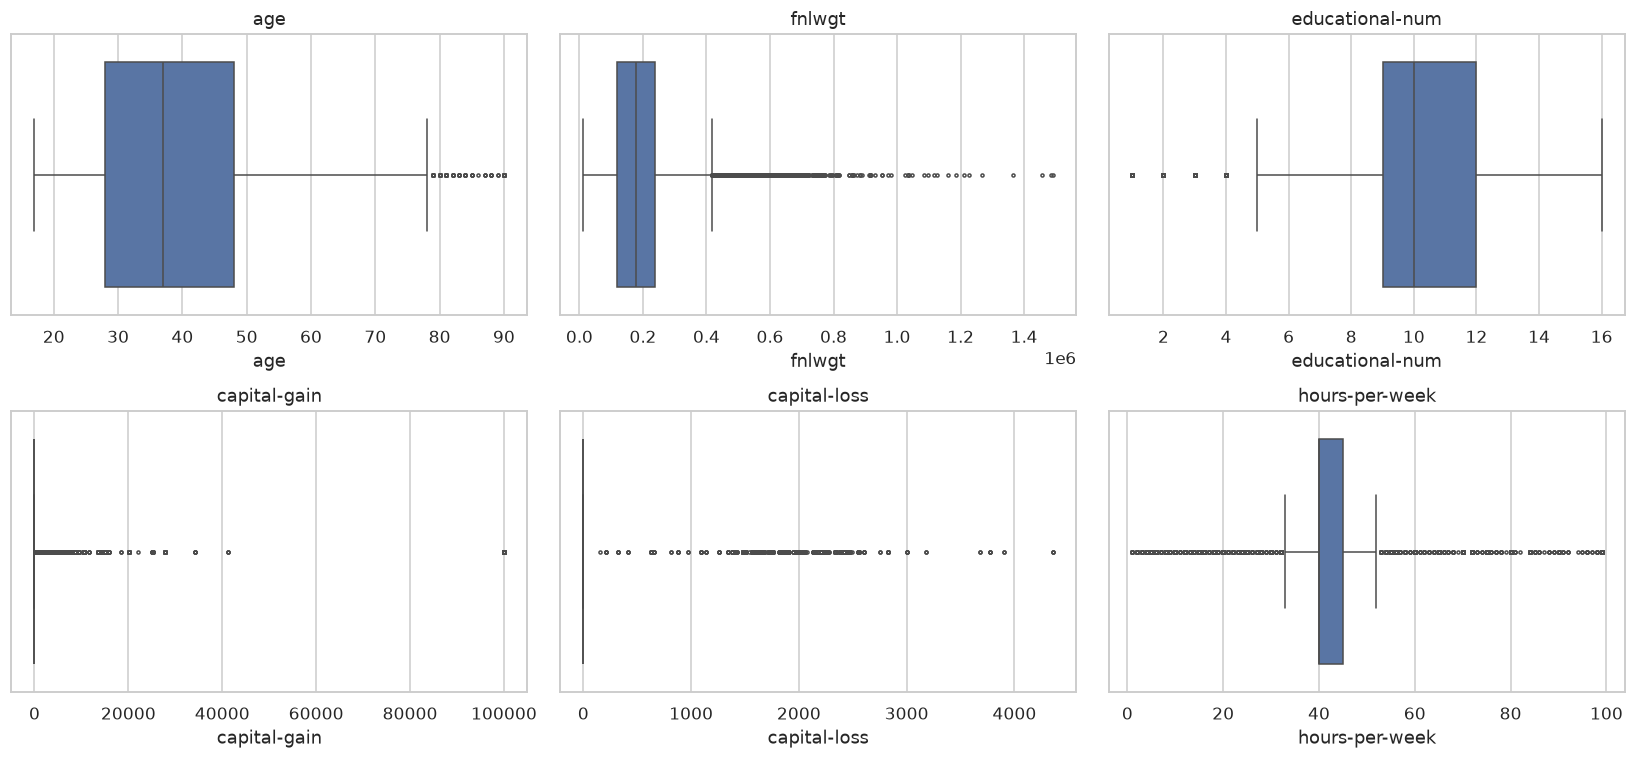

In [165]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[c], ax=ax, fliersize=2)
    ax.set_title(c)
fig.tight_layout()
plt.show()

In [166]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    m = (s < lo) | (s > hi)
    return pd.Series({
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower": lo, "upper": hi,
        "n_outliers": int(m.sum()),
    })

outlier_tbl = df[num_cols].apply(iqr_outliers).T
outlier_tbl

,Q1,Q3,IQR,lower,upper,n_outliers
age,28.0,48.0,20.0,-2.00,78.00,216.0
fnlwgt,117550.5,237642.0,120091.5,-62586.75,417779.25,1453.0
educational-num,9.0,12.0,3.0,4.50,16.50,1794.0
capital-gain,0.0,0.0,0.0,0.00,0.00,4035.0
capital-loss,0.0,0.0,0.0,0.00,0.00,2282.0
hours-per-week,40.0,45.0,5.0,32.50,52.50,13496.0


## 2.3 Outlier strategy

Chosen feature: capital-gain

Keep outlier but reshape scale because capital-gain distibution is likely to be real-world extreme than a simple error.

In [167]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {before - len(df)} exact duplicate rows -> {len(df):,} rows remain")

Dropped 52 exact duplicate rows -> 48,790 rows remain


# Phase 3 — Data Pre-processing

## 3.1 Handling missing values

Replace the ? with NaN

In [168]:
for c in cat_cols:
    df[c] = df[c].astype(str).str.strip()
df = df.replace("?", np.nan)

- workclass and occupation -> Unknown. 
- native-country -> impute with the mode (United-States).

In [169]:
country_mode = df["native-country"].mode()[0]
print(country_mode)

df["workclass"] = df["workclass"].fillna("Unknown")
df["occupation"] = df["occupation"].fillna("Unknown")
df["native-country"] = df["native-country"].fillna(country_mode)

United-States


## 3.2 Dropping the redundant column

In [170]:
df = df.drop(columns=["education"])
print("\nColumns after the drop:", list(df.columns))


Columns after the drop: ['age', 'workclass', 'fnlwgt', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


## 3.3 Categorical encoding

In [171]:
# 0/1
df["gender"] = (df["gender"] == "Male").astype(int)
df["income"] = (df["income"] == ">50K").astype(int)

df["capital-gain-topcoded"] = (df["capital-gain"] == 99999).astype(int)

nominal_cols = ["workclass", "marital-status", "occupation",
                "relationship", "race", "native-country"]

In [172]:
df_enc = pd.get_dummies(
    df,
    columns=nominal_cols,
    drop_first=True,   # drop one level per column -> avoids the dummy-variable trap
    dtype=int,
)
df_enc

,age,fnlwgt,educational-num,gender,capital-gain,capital-loss,hours-per-week,income,capital-gain-topcoded,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Unknown,workclass_Without-pay,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Armed-Forces,occupation_Craft-repair,...,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-US(Guam-USVI-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,25,226802,7,1,0,0,40,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,38,89814,9,1,0,0,50,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,28,336951,12,1,0,0,40,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,44,160323,10,1,7688,0,40,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,18,103497,10,0,0,0,30,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48785,27,257302,12,0,0,0,38,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
48786,40,154374,9,1,0,0,40,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
48787,58,151910,9,0,0,0,40,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
48788,22,201490,9,1,0,0,20,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0



# Scaling and Final Preparation

## 4.1 The skew transform decided in Phase 2

In [173]:
skew_before = df_enc[["capital-gain", "capital-loss"]].skew()

df_enc["capital-gain"] = np.log1p(df_enc["capital-gain"])
df_enc["capital-loss"] = np.log1p(df_enc["capital-loss"])

skew_after = df_enc[["capital-gain", "capital-loss"]].skew()

skew_cmp = pd.DataFrame({"skew before log1p": skew_before, "skew after log1p": skew_after})
skew_cmp.round(3)

,skew before log1p,skew after log1p
capital-gain,11.888,3.111
capital-loss,4.567,4.300


## 4.2 Feature scaling

Standardisation

In [174]:
from sklearn.model_selection import train_test_split

X = df_enc.drop(columns=["income"])
y = df_enc["income"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

In [175]:
from sklearn.preprocessing import StandardScaler

scale_cols = ["age", "fnlwgt", "educational-num",
              "capital-gain", "capital-loss", "hours-per-week"]

std_scaler = StandardScaler().fit(X_train[scale_cols])

X_train_std = X_train.copy()
X_test_std = X_test.copy()
X_train_std[scale_cols] = std_scaler.transform(X_train[scale_cols])
X_test_std[scale_cols] = std_scaler.transform(X_test[scale_cols])

summary = pd.DataFrame({
    "std-scaled mean": X_train_std[scale_cols].mean(),
    "std-scaled std": X_train_std[scale_cols].std(),

})
summary

,std-scaled mean,std-scaled std
age,2.020656e-16,1.000013
fnlwgt,2.330126e-17,1.000013
educational-num,3.185719e-16,1.000013
capital-gain,-2.912657e-17,1.000013
capital-loss,-5.461232e-18,1.000013
hours-per-week,-1.086785e-16,1.000013
